# 07 — Evaluación externa con fotos propias

**Fase CRISP-DM:** evaluación (generalización).

Los modelos finales (SVM `global_fruta` y CNN `doble`, ambos de dos clases) se aplican a las 18 fotos propias con el módulo `src/inference/predecir.py`, el mismo que usa la app. La fruta se le da al modelo de calidad; el clasificador de fruta se evalúa aparte.

- **Calidad:** se mide con las 12 fotos `buena` y `mala`, comparables con la prueba interna. Las 6 `regular` se analizan aparte (los modelos no tienen esa clase).
- **Limitaciones** (ver `docs/crisp-dm/05_evaluacion.md`): 18 fotos, sin escala, 4 `mala` con daño provocado y solo manzanas rojas.

In [1]:
import sys, os, json
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
os.environ["PYTHONPATH"] = str(RAIZ)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RESULTADOS, CLASES_ENTRENAMIENTO, FRUTAS_PROYECTO
from src.data.propias import cargar_etiquetas_propias
from src.data.recortes import leer_bgr, recorte_cuadrado
from src.evaluation.evaluar import metricas, graficar_matriz_confusion
from src.features.extraccion import CARACTERISTICAS_KAGGLE, extraer_caracteristicas
from src.inference.predecir import Clasificador
from src.utils.visualizacion import estilo, guardar_figura

estilo()
CLASES = CLASES_ENTRENAMIENTO
et = cargar_etiquetas_propias()
et["dano_provocado"] = et["notas"].str.contains("provocado")
clf = Clasificador(usar_cnn=True)

## 1. Predicciones

In [2]:
filas, recortes = [], {}
for _, r in et.iterrows():
    img = leer_bgr(r["ruta"])
    auto = clf.predecir(img)
    s = clf.predecir(img, fruta=r["fruta"], modelo="svm")
    c = clf.predecir(img, fruta=r["fruta"], modelo="cnn")
    recortes[r["archivo"]] = cv2.cvtColor(s.recorte, cv2.COLOR_BGR2RGB)
    filas.append({"archivo": r["archivo"], "fruta": r["fruta"], "calidad": r["calidad"],
                  "dano_provocado": r["dano_provocado"],
                  "fruta_auto": auto.fruta, "prob_fruta_auto": auto.prob_fruta,
                  "svm": s.calidad, "svm_prob_mala": s.probabilidades["mala"],
                  "cnn": c.calidad, "cnn_prob_mala": c.probabilidades["mala"],
                  "tiempo_svm_ms": s.tiempo_ms})
pred = pd.DataFrame(filas)
pred.round(3).to_csv(RESULTADOS / "externa_predicciones.csv", index=False)
pred.round(2)

,archivo,fruta,calidad,dano_provocado,fruta_auto,prob_fruta_auto,svm,svm_prob_mala,cnn,cnn_prob_mala,tiempo_svm_ms
0,jjl_banano_01.jpg,banano,buena,False,manzana,0.45,buena,0.30,buena,0.00,127.89
1,jjl_banano_02.jpg,banano,buena,False,manzana,0.36,buena,0.14,buena,0.00,144.92
2,jjl_banano_03.jpg,banano,regular,False,manzana,0.47,buena,0.13,buena,0.00,135.04
3,jjl_banano_04.jpg,banano,regular,False,manzana,0.47,buena,0.14,buena,0.00,151.04
4,jjl_banano_05.jpg,banano,mala,False,banano,0.47,buena,0.07,buena,0.05,89.20
5,jjl_banano_06.jpg,banano,mala,False,banano,0.56,buena,0.10,buena,0.06,102.80
6,jjl_manzana_01.jpg,manzana,buena,False,manzana,0.82,buena,0.06,mala,0.99,142.49
7,jjl_manzana_02.jpg,manzana,buena,False,manzana,0.74,buena,0.03,buena,0.32,135.05
8,jjl_manzana_03.jpg,manzana,regular,False,manzana,0.75,buena,0.10,buena,0.06,193.43
9,jjl_manzana_04.jpg,manzana,regular,False,manzana,0.82,buena,0.10,buena,0.03,217.74


## 2. Calidad en las fotos `buena` y `mala`

Mismas métricas que en la prueba interna, sobre 12 fotos (6 por clase). Con tan pocas fotos cada error mueve la exactitud en 8,3 puntos, así que los números son indicativos.

In [3]:
bm = pred[pred["calidad"].isin(CLASES)]
interna = pd.read_csv(RESULTADOS / "comparacion_modelos_test.csv").set_index("modelo")
filas = []
for m, nombre, ref in [("svm", "SVM (RBF)", "SVM (RBF)"), ("cnn", "CNN doble", "CNN doble")]:
    met = metricas(bm["calidad"], bm[m], CLASES, np.column_stack([1 - bm[f"{m}_prob_mala"], bm[f"{m}_prob_mala"]]))
    sin_prov = bm[~bm["dano_provocado"]]
    filas.append({"modelo": nombre, "f1_interna": interna.loc[ref, "f1_macro"], "f1_externa": met["f1_macro"],
                  "caida": interna.loc[ref, "f1_macro"] - met["f1_macro"], "exactitud": met["exactitud"],
                  "recall_buena": met["recall_buena"], "recall_mala": met["recall_mala"], "auc": met["auc"],
                  "exactitud_sin_dano_provocado": (sin_prov["calidad"] == sin_prov[m]).mean(),
                  "n_sin_dano_provocado": len(sin_prov)})
externa = pd.DataFrame(filas).set_index("modelo")
externa.round(3).to_csv(RESULTADOS / "externa_metricas.csv")
externa.round(3)

,f1_interna,f1_externa,caida,exactitud,recall_buena,recall_mala,auc,exactitud_sin_dano_provocado,n_sin_dano_provocado
modelo,,,,,,,,,
SVM (RBF),0.986,0.250,0.736,0.333,0.667,0.000,0.306,0.500,8
CNN doble,0.951,0.438,0.514,0.500,0.833,0.167,0.278,0.625,8


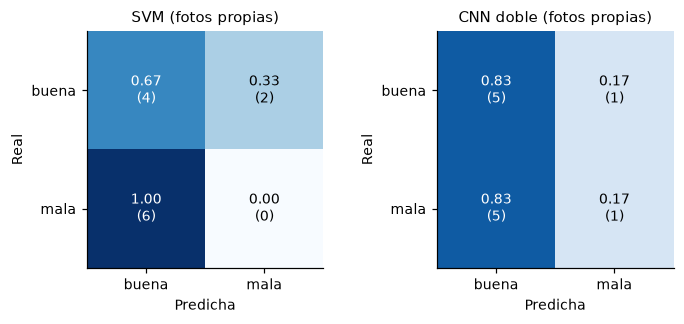

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(6.5, 3))
for ax, m, t in zip(axes, ["svm", "cnn"], ["SVM", "CNN doble"]):
    graficar_matriz_confusion(ax, bm["calidad"], bm[m], CLASES, f"{t} (fotos propias)")
fig.tight_layout()
guardar_figura(fig, "externa_matrices")
plt.show()

## 3. Probabilidad de `mala` por clase real

Si el modelo generalizara, las fotos `buena` tendrían probabilidad baja, las `mala` alta y las `regular` quedarían en medio.

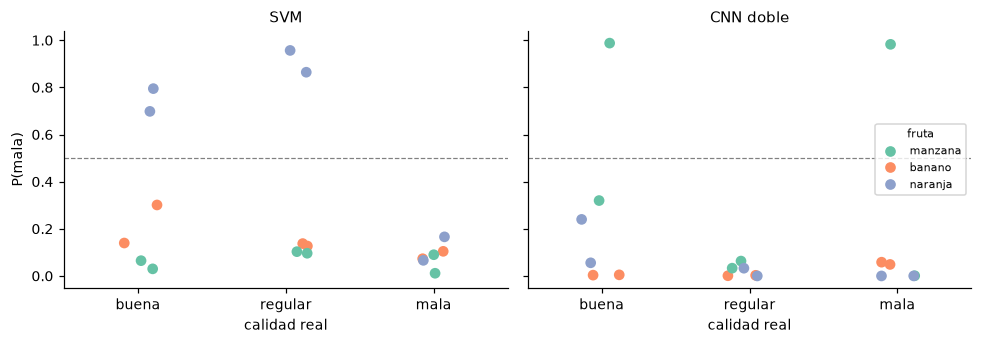

,svm_prob_mala,cnn_prob_mala
calidad,,
buena,0.220,0.148
mala,0.082,0.025
regular,0.132,0.018


In [5]:
largo = pred.melt(id_vars=["archivo", "fruta", "calidad", "dano_provocado"],
                  value_vars=["svm_prob_mala", "cnn_prob_mala"], var_name="modelo", value_name="prob_mala")
largo["modelo"] = largo["modelo"].map({"svm_prob_mala": "SVM", "cnn_prob_mala": "CNN doble"})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, m in zip(axes, ["SVM", "CNN doble"]):
    d = largo[largo["modelo"] == m]
    sns.stripplot(data=d, x="calidad", y="prob_mala", hue="fruta", order=["buena", "regular", "mala"],
                  hue_order=FRUTAS_PROYECTO, ax=ax, size=7, jitter=0.15, palette="Set2")
    ax.axhline(0.5, ls="--", c="gray", lw=0.8)
    ax.set_title(m, fontsize=10); ax.set_xlabel("calidad real"); ax.set_ylabel("P(mala)")
    if ax is axes[0]:
        ax.get_legend().remove()
axes[1].legend(fontsize=7, title="fruta", title_fontsize=7, loc="center right")
fig.tight_layout()
guardar_figura(fig, "externa_prob_mala")
plt.show()
pred.groupby("calidad")[["svm_prob_mala", "cnn_prob_mala"]].median().round(3)

## 4. ¿Por qué cae? Comparación con el dataset

Se ubican las fotos propias en la distribución de dos características de color del dataset (tono medio y $a^*$ medio de la fruta), por fruta y calidad. Si las fotos propias caen fuera de la nube de su clase, el modelo está extrapolando.

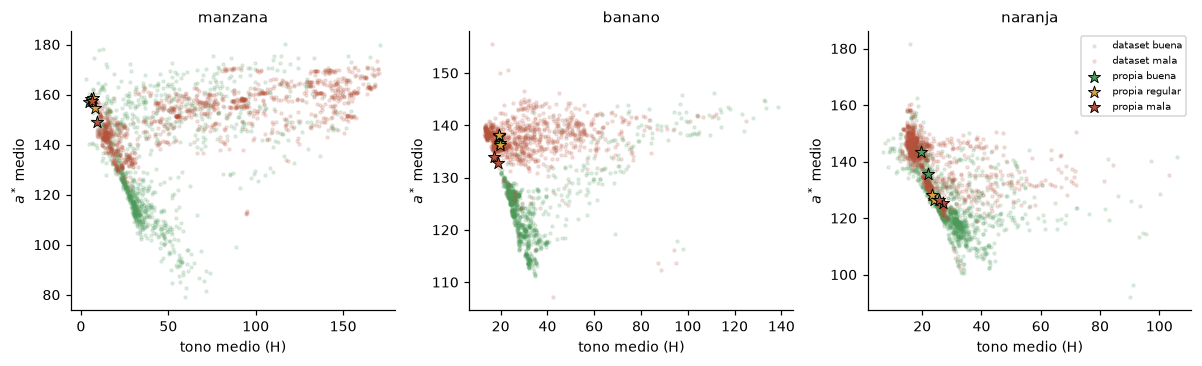

In [6]:
ds = pd.read_csv(CARACTERISTICAS_KAGGLE)
ds["calidad"] = ds["calidad_dataset"].map({"good": "buena", "bad": "mala"})
ds = ds[ds["fruta"].isin(FRUTAS_PROYECTO)]
prop = []
for _, r in et.iterrows():
    img = leer_bgr(r["ruta"])
    m = clf.predecir(img, fruta=r["fruta"]).mascara
    rec, rec_m = recorte_cuadrado(img, m)
    prop.append({"fruta": r["fruta"], "calidad": r["calidad"], **extraer_caracteristicas(rec, rec_m)})
prop = pd.DataFrame(prop)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
colores = {"buena": "#4c9a5a", "regular": "#d9a441", "mala": "#b5523b"}
for ax, f in zip(axes, FRUTAS_PROYECTO):
    d = ds[ds["fruta"] == f]
    for c in ("buena", "mala"):
        s = d[d["calidad"] == c]
        ax.scatter(s["mom_hsv_h_media"], s["mom_lab_a_media"], s=4, alpha=0.15, c=colores[c], label=f"dataset {c}")
    p = prop[prop["fruta"] == f]
    for c in ("buena", "regular", "mala"):
        s = p[p["calidad"] == c]
        ax.scatter(s["mom_hsv_h_media"], s["mom_lab_a_media"], s=70, marker="*", edgecolor="k", lw=0.6,
                   c=colores[c], label=f"propia {c}")
    ax.set_title(f, fontsize=10); ax.set_xlabel("tono medio (H)"); ax.set_ylabel("$a^*$ medio")
axes[-1].legend(fontsize=6.5, loc="best", markerscale=1)
fig.tight_layout()
guardar_figura(fig, "externa_dominio_color")
plt.show()

## 5. Errores

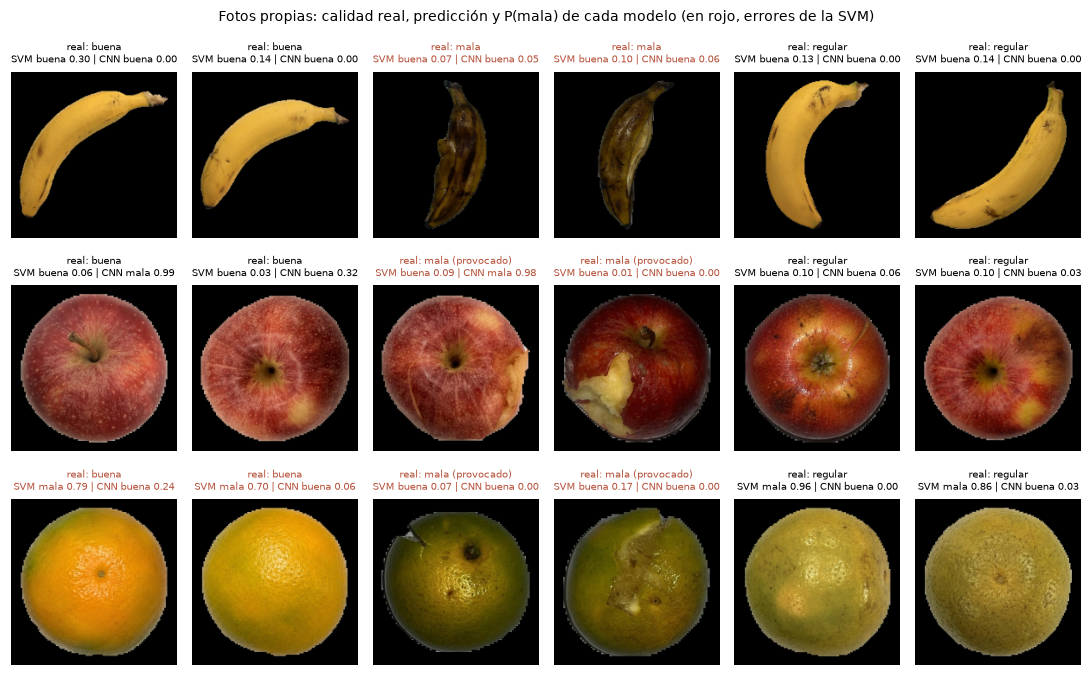

In [7]:
pred["acierto_svm"] = (pred["svm"] == pred["calidad"]) | (pred["calidad"] == "regular")
orden = pred.sort_values(["fruta", "calidad"])
fig, axes = plt.subplots(3, 6, figsize=(10, 6.4))
for ax, (_, r) in zip(axes.ravel(), orden.iterrows()):
    ax.imshow(recortes[r["archivo"]]); ax.axis("off")
    marca = " (provocado)" if r["dano_provocado"] else ""
    ax.set_title(f"real: {r['calidad']}{marca}\nSVM {r['svm']} {r['svm_prob_mala']:.2f} | CNN {r['cnn']} {r['cnn_prob_mala']:.2f}",
                 fontsize=6.3, color="black" if r["calidad"] == "regular" or r["svm"] == r["calidad"] else "#b5523b")
fig.suptitle("Fotos propias: calidad real, predicción y P(mala) de cada modelo (en rojo, errores de la SVM)", fontsize=9)
fig.tight_layout()
guardar_figura(fig, "externa_errores", raster=True, formatos=("png", "pdf"))
plt.show()

## 6. Reconocimiento automático de la fruta

In [8]:
acierto_fruta = (pred["fruta_auto"] == pred["fruta"])
print(f"Fruta reconocida: {acierto_fruta.sum()} de {len(pred)}")
pd.crosstab(pred["fruta"], pred["fruta_auto"])

Fruta reconocida: 12 de 18


fruta_auto,banano,manzana,naranja
fruta,,,
banano,2,4,0
manzana,0,6,0
naranja,0,2,4


## 7. Conclusiones\n\n1. **La generalización falla.** En las 12 fotos `buena`/`mala` el F1 macro cae de 0,986 a **0,25** con la SVM y de 0,951 a **0,44** con la CNN. El recall de `mala` es 0,00 y 0,17, y el AUC queda por debajo de 0,5 en ambos. No se cumple el criterio de éxito de generalización (F1 ≥ 0,70). Con 12 fotos el intervalo es muy ancho, pero la caída es demasiado grande para atribuirla al azar.
2. **Los modelos casi siempre dicen `buena`.** La SVM da P(mala) ≤ 0,30 a todos los bananos y manzanas, sin importar la calidad real, y P(mala) > 0,7 a las naranjas buenas y regulares. La probabilidad no ordena las clases (buena < regular < mala), así que no es un problema del umbral.
3. **Causa principal: el tipo de defecto.** En el espacio de color (sección 4), las fotos propias de cada fruta caen en un mismo punto sin importar su calidad. Sus defectos son **locales**: una mordida, piel arrancada, manchas pequeñas o la cáscara rasgada ocupan una fracción pequeña de la fruta. En el dataset la clase *bad* tiene sobre todo daño **global** (podredumbre, fruta ennegrecida), y por eso los modelos aprendieron a mirar el color medio de toda la fruta.
4. **Daño provocado.** Las 4 fotos `mala` con daño provocado muestran pulpa fresca y clara, un patrón que no existe en el entrenamiento. Sin ellas la exactitud sube a 0,50 (SVM) y 0,63 (CNN) sobre 8 fotos, todavía cerca del azar.
5. **Condiciones de captura.** Las fotos propias son nítidas, con luz blanca y fondo claro; el dataset tiene otra cámara, otra luz y otra nitidez. Las características de textura y color cambian con eso, y el notebook 03 mostró que esas condiciones predicen la calidad en el dataset (atajo).
6. **Reconocimiento de fruta: 12 de 18.** Falla sobre todo en banano (4 de 6 se confunden con manzana), por la misma diferencia de captura. En la app el usuario puede indicar la fruta.
7. **La CNN generaliza algo mejor que la SVM** (0,44 contra 0,25), al revés que en la prueba interna. Coincide con la hipótesis de que la SVM depende casi solo del color medio (notebook 03).

**Implicaciones.** El 0,986 interno mide qué tan bien se separa este dataset, no qué tan bien se clasifica una fruta real. Para mejorar haría falta: (a) entrenar con fotos tomadas en las condiciones de uso, incluidas las propias; (b) características locales de defecto (proporción y tamaño de manchas, no solo el color medio); (c) aumentación de color y brillo en la CNN, o *transfer learning*; y (d) etiquetas de daño natural y no provocado.